# Can Machine Learning Detect Prompt Injection Attacks?

Independent data audit of Dzhaliuk et al. (2026), an empirical comparison of machine-learning defenses for prompt injection. A prompt-injection detector may reduce data-leak risk, but this dataset labels text as benign or malicious; it does not measure whether an AI agent actually leaks a secret.

The notebook downloads the public train/test Parquet files from Hugging Face if they are not present beside the notebook. Requires pandas, pyarrow, scikit-learn and matplotlib.

In [1]:
from pathlib import Path
import urllib.request, pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score

BASE = 'https://huggingface.co/datasets/jayavibhav/prompt-injection/resolve/main/data/'
for name, filename in [('train','train-00000-of-00001.parquet'),('test','test-00000-of-00001.parquet')]:
    path=Path(f'{name}.parquet')
    if not path.exists():
        urllib.request.urlretrieve(BASE+filename, path)
train=pd.read_parquet('train.parquet'); test=pd.read_parquet('test.parquet')
print('Train:',train.shape,' Test:',test.shape,' Combined:',len(train)+len(test))
print('Columns:',train.columns.tolist())
print('Train labels:',train.label.value_counts().sort_index().to_dict())
print('Test labels:',test.label.value_counts().sort_index().to_dict())

Train: (261738, 2)  Test: (65416, 2)  Combined: 327154
Columns: ['text', 'label']
Train labels: {0: 132506, 1: 129232}
Test labels: {0: 33122, 1: 32294}


## Data-quality audit

The article says the dataset has 327,400 rows. Its listed train/test label counts add to 340,238. Compare those statements with the downloaded files. Check blank text, duplicates, split overlap and prompt lengths.

In [3]:
article_total=327400
article_train=128380+146720
article_test=32046+33092
print('Public file rows:',len(train)+len(test))
print('Article stated total:',article_total)
print('Article split counts sum:',article_train+article_test)
print('Missing train cells:',train.isna().sum().to_dict())
print('Missing test cells:',test.isna().sum().to_dict())
print('Blank train prompts:',int(train.text.fillna('').str.strip().eq('').sum()))
print('Blank test prompts:',int(test.text.fillna('').str.strip().eq('').sum()))
print('Duplicate full rows, train/test:',int(train.duplicated().sum()),int(test.duplicated().sum()))
print('Duplicate texts, train/test:',int(train.text.duplicated().sum()),int(test.text.duplicated().sum()))
overlap=set(train.text.dropna()).intersection(set(test.text.dropna()))
print('Exact texts appearing in both splits:',len(overlap))
print('Train/test label proportions:',train.label.value_counts(normalize=True).round(4).to_dict(),test.label.value_counts(normalize=True).round(4).to_dict())
print('Character length quantiles, train:',train.text.str.len().quantile([.5,.9,.99]).round(1).to_dict())

Public file rows: 327154
Article stated total: 327400
Article split counts sum: 340238
Missing train cells: {'text': 0, 'label': 0}
Missing test cells: {'text': 0, 'label': 0}
Blank train prompts: 0
Blank test prompts: 1
Duplicate full rows, train/test: 112 11
Duplicate texts, train/test: 117 12
Exact texts appearing in both splits: 36
Train/test label proportions: {0: 0.5063, 1: 0.4937} {0: 0.5063, 1: 0.4937}
Character length quantiles, train: {0.5: 350.0, 0.9: 593.0, 0.99: 899.0}


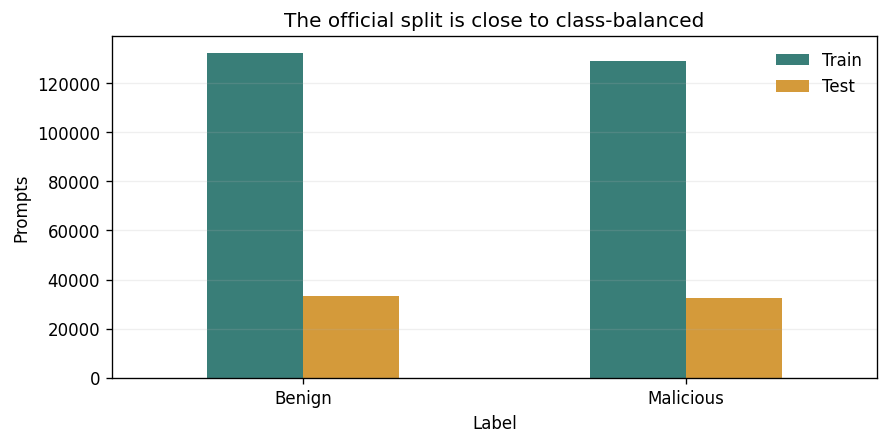

In [4]:
# Figure 1: class counts by official split
counts=pd.DataFrame({'Train':train.label.value_counts().sort_index(),'Test':test.label.value_counts().sort_index()},index=[0,1])
ax=counts.rename(index={0:'Benign',1:'Malicious'}).plot(kind='bar',figsize=(7.5,3.8),color=['#397E78','#D49A3A'])
ax.set(title='The official split is close to class-balanced',xlabel='Label',ylabel='Prompts'); ax.legend(frameon=False); ax.grid(axis='y',alpha=.2); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

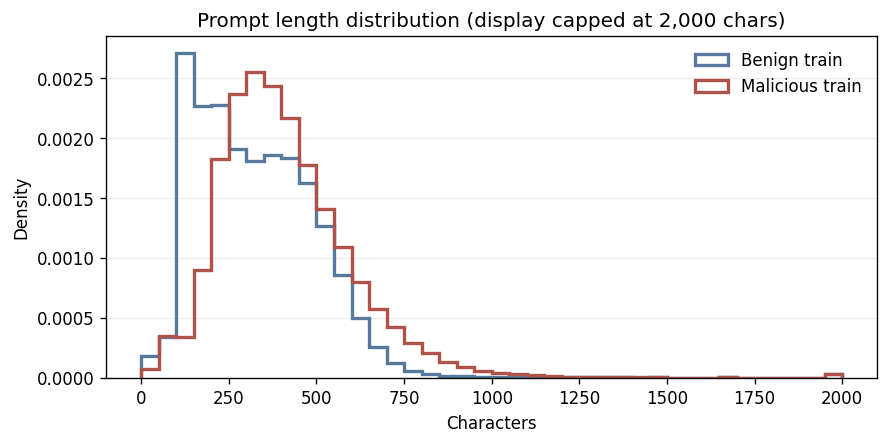

In [5]:
# Figure 2: length distributions, with extreme outliers omitted from the display only
fig,ax=plt.subplots(figsize=(7.5,3.8))
for d,label,color in [(train[train.label==0],'Benign train','#557A9C'),(train[train.label==1],'Malicious train','#B05247')]:
    ax.hist(d.text.str.len().clip(upper=2000),bins=np.arange(0,2001,50),density=True,histtype='step',lw=2,label=label,color=color)
ax.set(title='Prompt length distribution (display capped at 2,000 chars)',xlabel='Characters',ylabel='Density'); ax.legend(frameon=False); ax.grid(axis='y',alpha=.2); plt.tight_layout(); plt.show()

## Independent baseline

Train a TF–IDF Logistic Regression model on a stratified 50,000-row sample of the official training split. Evaluate against the official test split, excluding its one blank prompt. This is an independent baseline, not a reproduction of the paper’s embedding and transformer pipelines.

In [7]:
train_sample,_=train_test_split(train,test_size=len(train)-50000,stratify=train.label,random_state=42)
test_eval=test[test.text.fillna('').str.strip().ne('')].copy()
vectorizer=TfidfVectorizer(ngram_range=(1,2),max_features=30000,min_df=2,sublinear_tf=True,strip_accents='unicode',dtype=np.float32)
X_train=vectorizer.fit_transform(train_sample.text.astype(str)); X_test=vectorizer.transform(test_eval.text.astype(str))
model=LogisticRegression(max_iter=200,C=2,solver='liblinear',random_state=42)
model.fit(X_train,train_sample.label)
pred=model.predict(X_test); prob=model.predict_proba(X_test)[:,1]
precision,recall,f1,_=precision_recall_fscore_support(test_eval.label,pred,average='binary')
cm=confusion_matrix(test_eval.label,pred)
print('Training sample:',len(train_sample),' Held-out test rows:',len(test_eval))
print({'accuracy':round(accuracy_score(test_eval.label,pred),4),'malicious_precision':round(precision,4),'malicious_recall':round(recall,4),'malicious_F1':round(f1,4),'ROC_AUC':round(roc_auc_score(test_eval.label,prob),4)})
print('Confusion matrix [[TN,FP],[FN,TP]]:'); print(cm)

Training sample: 50000  Held-out test rows: 65415
{'accuracy': 0.9768, 'malicious_precision': 0.983, 'malicious_recall': 0.9697, 'malicious_F1': 0.9763, 'ROC_AUC': 0.9964}
Confusion matrix [[TN,FP],[FN,TP]]:
[[32579   542]
 [  978 31316]]


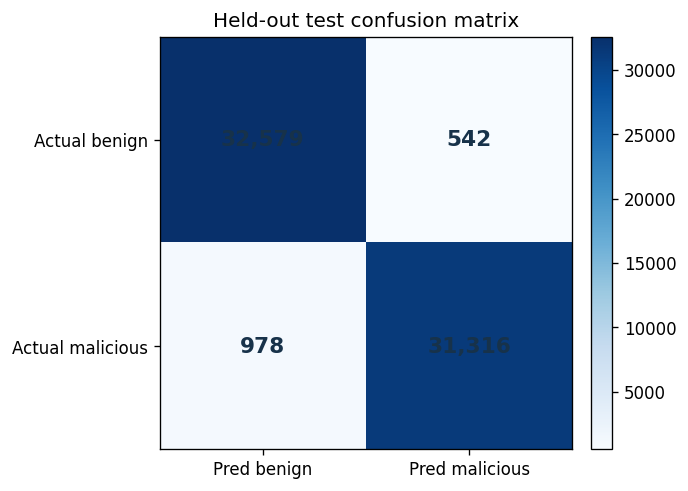

In [8]:
fig,ax=plt.subplots(figsize=(5.4,4.2)); im=ax.imshow(cm,cmap='Blues'); ax.set_xticks([0,1],['Pred benign','Pred malicious']); ax.set_yticks([0,1],['Actual benign','Actual malicious']); ax.set_title('Held-out test confusion matrix')
for i in range(2):
    for j in range(2): ax.text(j,i,f'{cm[i,j]:,}',ha='center',va='center',color='#17324A',fontsize=13,fontweight='bold')
fig.colorbar(im,ax=ax,fraction=.045,pad=.04); plt.tight_layout(); plt.show()

## Interpretation

The classifier’s benchmark score does not establish that an LLM agent will resist an attack or prevent a secret from being exfiltrated. The dataset is nearly balanced, uses a single benchmark source, contains repeated prompts across the official split, and includes one blank test item. A stronger study would group duplicates before splitting, add independently sourced attacks and benign samples, measure performance at realistic attack prevalence, and record actual agent-level data-exfiltration outcomes.